In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error, structural_similarity

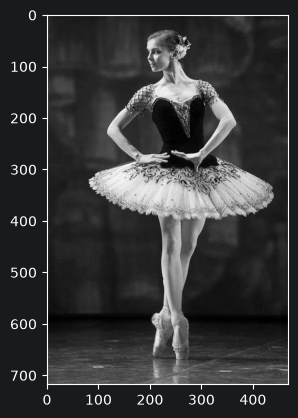

In [4]:
image = cv2.imread('pict_2.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')
plt.show()

[[  0   0  20 ...   0  90   2]
 [ 11   4  30 ...   0   0  46]
 [  0   0 122 ...   5   0  57]
 ...
 [194 173   0 ...   0   5  56]
 [ 76  81   0 ...   6   0   0]
 [180   0  86 ...   0  34   0]]


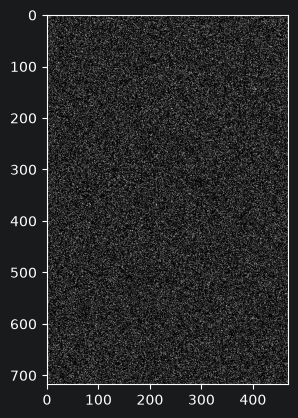

In [10]:
# гаусс
mean = 0 # мю
stddev = 100 # сигма
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)
print(noise_gauss)
plt.imshow(noise_gauss, cmap="gray")

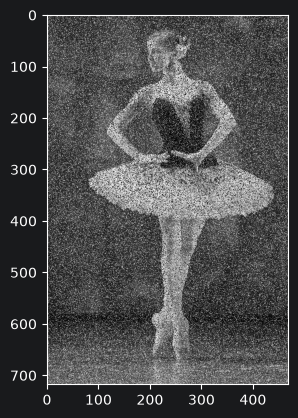

In [11]:
image_noise_gauss = image_gray + noise_gauss
plt.imshow(image_noise_gauss, cmap="gray")
plt.show()

[[34 21 61 ... 29 56  5]
 [37 64 63 ... 20 20 96]
 [53 53 46 ... 99 81 84]
 ...
 [52 60 94 ... 65 27 16]
 [29 33 31 ... 60 43 83]
 [86 57 57 ... 18 51 34]]


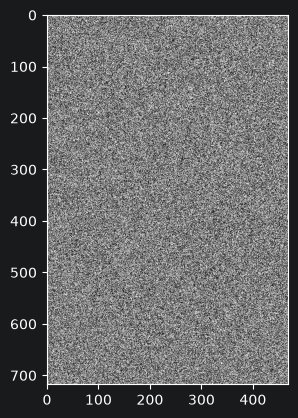

In [12]:
# постоянный
noise_uniform = np.zeros(image_gray.shape, np.uint8)
cv2.randu(noise_uniform, 0, 100)
print(noise_uniform)
plt.imshow(noise_uniform, cmap="gray")
plt.show()

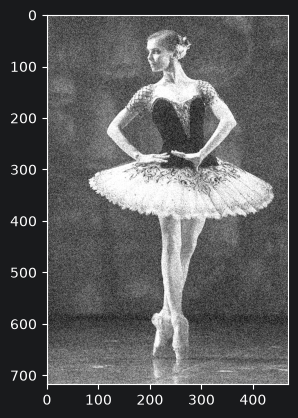

In [13]:
image_noise_uniform = cv2.add(image_gray, noise_uniform)
plt.imshow(image_noise_uniform, cmap="gray")
plt.show()

In [51]:
# ФИЛЬТРЫ

In [14]:
# медианный по гауссу
image_gauss_median_3 = cv2.medianBlur(image_noise_gauss, 3)
image_gauss_median_7 = cv2.medianBlur(image_noise_gauss, 7)

In [16]:
# гаусс и медианный 3
mse_gauss_median_cleared_3 = mean_squared_error(image_gray, image_gauss_median_3)
(ssim_gauss_median_cleared_3, diff) = structural_similarity(image_gray, image_gauss_median_3, full=True)
print(mse_gauss_median_cleared_3, ssim_gauss_median_cleared_3)

851.6266637366292 0.25868369817105263


In [17]:
# гаусс и медианный 7
mse_gauss_median_cleared_7 = mean_squared_error(image_gray, image_gauss_median_7)
(ssim_gauss_median_cleared_7, diff) = structural_similarity(image_gray, image_gauss_median_7, full=True)
print(mse_gauss_median_cleared_7, ssim_gauss_median_cleared_7)

348.64285714285717 0.5918592562792032


In [19]:
# медианный по постоянному
image_uniform_median_3 = cv2.medianBlur(image_noise_uniform, 3)
image_uniform_median_7 = cv2.medianBlur(image_noise_uniform, 7)

In [23]:
# постоянный и медианный 3
mse_uniform_median_cleared_3 = mean_squared_error(image_gray, image_uniform_median_3)
(ssim_uniform_median_cleared_3, diff) = structural_similarity(image_gray, image_uniform_median_3, full=True)
print(mse_uniform_median_cleared_3, ssim_uniform_median_cleared_3)

2712.3252876089114 0.2933227039590811


In [22]:
# постоянный и медианный 7
mse_uniform_median_cleared_7 = mean_squared_error(image_gray, image_uniform_median_7)
(ssim_uniform_median_cleared_7, diff) = structural_similarity(image_gray, image_uniform_median_7, full=True)
print(mse_uniform_median_cleared_7, ssim_uniform_median_cleared_7)

2651.5644350868024 0.47518889660715086


In [24]:
# фильтр гаусса по шуму гаусса
image_gauss_gauss_3 = cv2.GaussianBlur(image_noise_gauss,(3,3),0)
image_gauss_gauss_7 = cv2.GaussianBlur(image_noise_gauss,(7,7),0)

In [27]:
# гаусс и гаусс 3
mse_gauss_gauss_cleared_3 = mean_squared_error(image_gray, image_gauss_gauss_3)
(ssim_gauss_gauss_cleared_3, diff) = structural_similarity(image_gray, image_gauss_gauss_3, full=True)
print(mse_gauss_gauss_cleared_3, ssim_gauss_gauss_cleared_3)

1700.3328245362918 0.20432028446350167


In [28]:
# гаусс и гаусс 7
mse_gauss_gauss_cleared_7 = mean_squared_error(image_gray, image_gauss_gauss_7)
(ssim_gauss_gauss_cleared_7, diff) = structural_similarity(image_gray, image_gauss_gauss_7, full=True)
print(mse_gauss_gauss_cleared_7, ssim_gauss_gauss_cleared_7)

1457.026489122236 0.3828634852177916


In [29]:
# фильтр гаусса по постоянному шуму
image_uniform_gauss_3 = cv2.GaussianBlur(image_noise_uniform,(3,3),0)
image_uniform_gauss_7 = cv2.GaussianBlur(image_noise_uniform,(7,7),0)

In [30]:
# постоянный и гаусс 3
mse_uniform_gauss_cleared_3 = mean_squared_error(image_gray, image_uniform_gauss_3)
(ssim_uniform_gauss_cleared_3, diff) = structural_similarity(image_gray, image_uniform_gauss_3, full=True)
print(mse_uniform_gauss_cleared_3, ssim_uniform_gauss_cleared_3)

2535.892321124184 0.3903789940097698


In [31]:
# постоянный и гаусс 7
mse_uniform_gauss_cleared_7 = mean_squared_error(image_gray, image_uniform_gauss_7)
(ssim_uniform_gauss_cleared_7, diff) = structural_similarity(image_gray, image_uniform_gauss_7, full=True)
print(mse_uniform_gauss_cleared_7, ssim_uniform_gauss_cleared_7)

2523.3769295187412 0.5325760431516912


In [33]:
# билатериальный фильтр по шуму гаусса
image_gauss_bilat_1 = cv2.bilateralFilter(image_noise_gauss,9,75,75)
image_gauss_bilat_2 = cv2.bilateralFilter(image_noise_gauss,49,150,150)

In [34]:
# гаусс и билатериальный 1
mse_gauss_bilat_cleared_1 = mean_squared_error(image_gray, image_gauss_bilat_1)
(ssim_gauss_bilat_cleared_1, diff) = structural_similarity(image_gray, image_gauss_bilat_1, full=True)
print(mse_gauss_bilat_cleared_1, ssim_gauss_bilat_cleared_1)

1714.1211877342298 0.16975519375622253


In [35]:
# гаусс и билатериальный 2
mse_gauss_bilat_cleared_2 = mean_squared_error(image_gray, image_gauss_bilat_2)
(ssim_gauss_bilat_cleared_2, diff) = structural_similarity(image_gray, image_gauss_bilat_2, full=True)
print(mse_gauss_bilat_cleared_2, ssim_gauss_bilat_cleared_2)

1570.9207880216902 0.3900554500400799


In [47]:
# билатериальный фильтр по постоянному шуму
image_uniform_bilat_1 = cv2.bilateralFilter(image_noise_uniform,9,75,75)
image_uniform_bilat_2 = cv2.bilateralFilter(image_noise_uniform,49,150,150)

In [37]:
# постоянный и билатериальный 1
mse_uniform_bilat_cleared_1 = mean_squared_error(image_gray, image_uniform_bilat_1)
(ssim_uniform_bilat_cleared_1, diff) = structural_similarity(image_gray, image_uniform_bilat_1, full=True)
print(mse_uniform_bilat_cleared_1, ssim_uniform_bilat_cleared_1)

2495.273690243569 0.5271609256089731


In [38]:
# постоянный и билатериальный 2
mse_uniform_bilat_cleared_2 = mean_squared_error(image_gray, image_uniform_bilat_2)
(ssim_uniform_bilat_cleared_2, diff) = structural_similarity(image_gray, image_uniform_bilat_2, full=True)
print(mse_uniform_bilat_cleared_2, ssim_uniform_bilat_cleared_2)

2863.7405639926114 0.5238105833115558


In [39]:
# фильтр нелокальных средних по шуму гауссу
image_gauss_nlm_1 = cv2.fastNlMeansDenoising(image_noise_gauss, h = 5)
image_gauss_nlm_2 = cv2.fastNlMeansDenoising(image_noise_gauss, h = 75)
image_gauss_nlm_3 = cv2.fastNlMeansDenoising(image_noise_gauss, h = 150)

In [40]:
# гаусс и нелокальных средних 5
mse_gauss_nlm_cleared_1 = mean_squared_error(image_gray, image_gauss_nlm_1)
(ssim_gauss_nlm_cleared_1, diff) = structural_similarity(image_gray, image_gauss_nlm_1, full=True)
print(mse_gauss_nlm_cleared_1, ssim_gauss_nlm_cleared_1)

1474.669411597009 0.570756414737587


In [41]:
# гаусс и нелокальных средних 75
mse_gauss_nlm_cleared_2 = mean_squared_error(image_gray, image_gauss_nlm_2)
(ssim_gauss_nlm_cleared_2, diff) = structural_similarity(image_gray, image_gauss_nlm_2, full=True)
print(mse_gauss_nlm_cleared_2, ssim_gauss_nlm_cleared_2)

1573.0199915662436 0.5632670614365886


In [42]:
# гаусс и нелокальных средних 150
mse_gauss_nlm_cleared_3 = mean_squared_error(image_gray, image_gauss_nlm_3)
(ssim_gauss_nlm_cleared_3, diff) = structural_similarity(image_gray, image_gauss_nlm_3, full=True)
print(mse_gauss_nlm_cleared_3, ssim_gauss_nlm_cleared_3)

4200.917527365164 0.07273186538629949


In [43]:
# фильтр нелокальных средних по постоянному шуму
image_uniform_nlm_1 = cv2.fastNlMeansDenoising(image_noise_uniform, h = 5)
image_uniform_nlm_2 = cv2.fastNlMeansDenoising(image_noise_uniform, h = 75)
image_uniform_nlm_3 = cv2.fastNlMeansDenoising(image_noise_uniform, h = 150)

In [44]:
# постоянный и нелокальных средних 5
mse_uniform_nlm_cleared_1 = mean_squared_error(image_gray, image_uniform_nlm_1)
(ssim_uniform_nlm_cleared_1, diff) = structural_similarity(image_gray, image_uniform_nlm_1, full=True)
print(mse_uniform_nlm_cleared_1, ssim_uniform_nlm_cleared_1)

3142.432170623207 0.1936134864438572


In [45]:
# постоянный и нелокальных средних 75
mse_uniform_nlm_cleared_2 = mean_squared_error(image_gray, image_uniform_nlm_2)
(ssim_uniform_nlm_cleared_2, diff) = structural_similarity(image_gray, image_uniform_nlm_2, full=True)
print(mse_uniform_nlm_cleared_2, ssim_uniform_nlm_cleared_2)

2593.6581091755706 0.5666396395446721


In [46]:
# постоянный и нелокальных средних 150
mse_uniform_nlm_cleared_3 = mean_squared_error(image_gray, image_uniform_nlm_3)
(ssim_uniform_nlm_cleared_3, diff) = structural_similarity(image_gray, image_uniform_nlm_3, full=True)
print(mse_uniform_nlm_cleared_3, ssim_uniform_nlm_cleared_3)

2714.4797500757254 0.5307569234100735


In [50]:
# ЛУЧШИЕ РЕЗУЛЬТАТЫ
# Для шума Гаусса: Медианный 7 348.64285714285717 0.5918592562792032
# Для постоянного шума: Билатериальный 1 2495.273690243569 0.5271609256089731

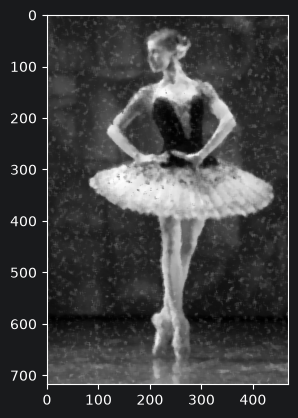

In [48]:
plt.imshow(image_gauss_median_7, cmap="gray")
plt.show()

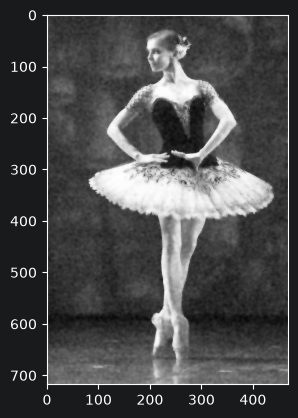

In [49]:
plt.imshow(image_uniform_bilat_1, cmap="gray")
plt.show()